In [1]:
#@title Imports and hyperparameters
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from helpers import gather_seeds

# Hyperparameters
unmask_every = 3
#dataset = 'triangle'
dataset = 'tmaze'

In [2]:
# Gather seeds
seeds = gather_seeds(f'{dataset}_dataset', f'unmask_every_{unmask_every}__noleak')
if dataset == 'triangle':
    seeds = [s for s in seeds if s != 4] # seed 4 is bad
elif dataset == 'tmaze':
    seeds = [s for s in seeds if s != 3] # seed 3 is bad
seeds = list(set(seeds)) # keep only unique values, since there are noleak seeds, too
print(seeds)

[0, 1, 2, 4, 5]


In [3]:
losses = []
noleak_losses = []
for s in seeds:
    prefix = f"{dataset}_dataset__unmask_every_{unmask_every}"
    suffix = f"__seed_{s :02d}__extra.npz"    
    for middle, arr in zip(["", "__noleak"], [losses, noleak_losses]):
        fname = prefix + middle + suffix
        arr.append(np.load("results/" + fname)['loss'])
losses = np.stack(losses)
noleak_losses = np.stack(noleak_losses)

Text(0.5, 0.98, 'tmaze loss')

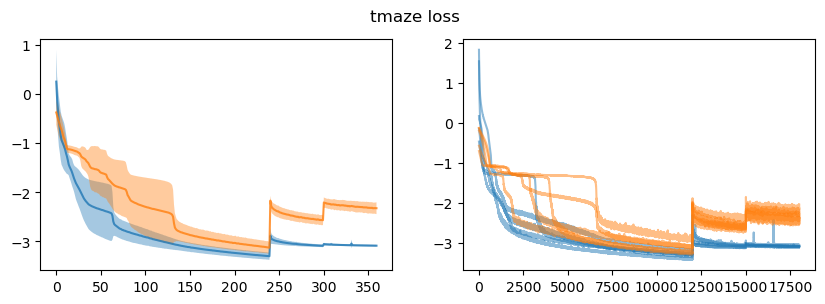

In [4]:
# downsample by a factor of 50 via averaging
ds = 50
df = pd.DataFrame([np.log(losses).mean(0).reshape(-1,ds).mean(1), 
                   np.log(losses).std(0).reshape(-1,ds).mean(1),
                   np.log(noleak_losses).mean(0).reshape(-1,ds).mean(1), 
                   np.log(noleak_losses).std(0).reshape(-1,ds).mean(1)]).T
df.columns = ['log_mean', 'log_std', 'noleak_log_mean', 'noleak_log_std']


fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10,3))

axs[0].fill_between(df.index, df.log_mean - df.log_std, df.log_mean + df.log_std, alpha=0.4)
axs[0].fill_between(df.index, df.noleak_log_mean - df.noleak_log_std,
                              df.noleak_log_mean + df.noleak_log_std, alpha=0.4)
axs[0].plot(df.index, df.log_mean, c='C0', alpha=0.8)
axs[0].plot(df.index, df.noleak_log_mean, c='C1', alpha=0.8)

axs[1].plot(np.log(losses).T, alpha=0.5, c='C0')
axs[1].plot(np.log(noleak_losses).T, alpha=0.5, c='C1')

fig.suptitle(f'{dataset} loss')

In [5]:
df.to_csv(f'csv/leak_losses_{dataset}.csv')
df

,log_mean,log_std,noleak_log_mean,noleak_log_std
0,0.254481,0.649076,-0.373747,0.250693
1,-0.106201,0.465334,-0.438070,0.264674
2,-0.353771,0.483159,-0.504305,0.277181
3,-0.557722,0.510403,-0.571361,0.285560
4,-0.693642,0.498219,-0.628508,0.279312
...,...,...,...,...
355,-3.086902,0.017236,-2.325192,0.115144
356,-3.086983,0.017163,-2.322885,0.112225
357,-3.087605,0.017304,-2.322776,0.113428
358,-3.087317,0.017420,-2.324144,0.116531
